# Introduction

In part 1 of this assessment, you will complete several requested SQL queries in order to extract data, analyze, and provide insights from a single provided SQL database. You will also visualize the key results of 3 of these queries. There are also several 'Reflection' questions that ask you to write out a text based answer in the provided markdown cell. Following the guided question and answer section, in part 2 you will explore a second dataset on your own using SQL in order to conduct a preliminary analysis. You will be asked to produce a very short slide presentation highlighting the work you did for this second section.

## Objectives
You will be able to:
- Interpret "word problems" and translate them into SQL queries
- Decide and perform whichever type of JOIN is best for retrieving desired data
- Use GROUP BY statements to apply aggregate functions like COUNT, MAX, MIN, and SUM
- Use the HAVING clause to compare different aggregates
- Write subqueries to decompose complex queries
- Visualize data using matplotlib, seaborn, or pandas
- Choose the correct chart type based on the given data


## Part 1: Guided SQL Queries

### Your Task: Querying a Customer Database

![toy car picture](images/toycars.jpg)


### Business Understanding
Your employer sells wholesale miniature models of products such as classic cars, motorcycles, and planes. They want you to pull several reports on different segments of their past customers, in order to better understand past sales as well as determine which customers will receive promotional material. They are also interested in investigating which products have performed the best, as well as having several smaller asks.

In addition to providing the requested data from the SQL database you have also been asked to create some basic visuals to display some of the more insightful information. It is up to your discretion to choose the correct plot/chart type for the data in question. **Questions that want you to visualize the results will be explicitly marked**.

### Data Understanding
You may remember this database from a previous lab. As a refresher, here's the ERD diagram for this database:

![ERD picture](images/ERD.png)

The queries you are asked to write will become more complex over the course of the lab.



### Getting Started
For this assessment you are expected to make use of both sqlite3 and the Pandas libraries in order to write, execute, and return SQL queries as a Pandas DataFrame. Assign each returned answer as its own explicit variable.

For the visualization piece you are expected to utilize either Pandas, Seaborn, or Matplotlib to create your visuals. Make sure you are providing verbose labels and titles according to the data you are being asked to visualize. Do not worry too much about choosing a 'style' or 'context' instead focus on conveying the requested information correctly.

### Step 1: Connect to Data

In the cell below
- Import the necessary libraries
- Establish a connection to the database data.sqlite

In [1]:
# Replace None with your code
# Imports
import sqlite3
import pandas as pd
# Create connection to database
conn = sqlite3.connect('data.sqlite')

In [2]:
#Check if the connection was successful.
pd.read_sql('''SELECT name FROM sqlite_master WHERE type = 'table';''', conn)

,name
0,orderdetails
1,payments
2,offices
3,customers
4,orders
5,productlines
6,products
7,employees


### Step 2: Limited Edition California Product
The California sales rep team is interested in running promotional material for a new limited edition model they are releasing based on the famous San Francisco Cable Cars. This product will only be available to customer stores based in California and given its high price value they want to first target promotional material to existing California customers with a high credit limit. Upon communicating with the accounting department, a credit limit of over 25,000 is considered to be high. 

Execute a SQl query that returns which customers the sales rep team wants to market to first.
*Hint*: Make sure creditLimit is numeric.

In [3]:
# Replace None with your code
high_credit_query = ''' 
SELECT customerNumber, 
        customerName,
        contactFirstName,
        contactLastName,
        phone,
        addressLine1,
        addressLine2,
        city,
        state,
        postalCode,
CAST(creditLimit AS REAL) AS creditLimit
FROM customers
WHERE state = 'CA' 
AND CAST(creditLimit AS REAL)>25000;'''
#added the address and contact information incase the sales team want to reach out to the customers or want to send any promotional materail they may have to the address.
high_credit = pd.read_sql(high_credit_query,conn)
high_credit

,customerNumber,customerName,contactFirstName,contactLastName,phone,addressLine1,addressLine2,city,state,postalCode,creditLimit
0,124,Mini Gifts Distributors Ltd.,Susan,Nelson,4155551450,5677 Strong St.,,San Rafael,CA,97562,210500.0
1,129,Mini Wheels Co.,Julie,Murphy,6505555787,5557 North Pendale Street,,San Francisco,CA,94217,64600.0
2,161,Technics Stores Inc.,Juri,Hashimoto,6505556809,9408 Furth Circle,,Burlingame,CA,94217,84600.0
3,205,Toys4GrownUps.com,Julie,Young,6265557265,78934 Hillside Dr.,,Pasadena,CA,90003,90700.0
4,239,Collectable Mini Designs Co.,Valarie,Thompson,7605558146,361 Furth Circle,,San Diego,CA,91217,105000.0
5,321,Corporate Gift Ideas Co.,Julie,Brown,6505551386,7734 Strong St.,,San Francisco,CA,94217,105000.0
6,347,"Men 'R' US Retailers, Ltd.",Brian,Chandler,2155554369,6047 Douglas Av.,,Los Angeles,CA,91003,57700.0
7,450,The Sharp Gifts Warehouse,Sue,Frick,4085553659,3086 Ingle Ln.,,San Jose,CA,94217,77600.0
8,475,West Coast Collectables Co.,Steve,Thompson,3105553722,3675 Furth Circle,,Burbank,CA,94019,55400.0
9,487,Signal Collectibles Ltd.,Sue,Taylor,4155554312,2793 Furth Circle,,Brisbane,CA,94217,60300.0


### Step 3: International Collectable Campaign

The international sales rep team has reached out to you to help them identify partners for a 'Collectable' marketing campaign that highlights the potential collectors value in purchasing these model kits. They want to try and promote a 'collect them all' mentality. The team had a great idea to partner with any of their international customers (non-US) who have "Collect" in their name as a tie in to the larger theme.

Execute a SQL that returns the customers in question.

In [4]:
# Replace None with your code
collect_query = '''
SELECT customerNumber,
       customerName,
       contactFirstName,
       contactLastName,
       phone,
       city,
       country
FROM customers
WHERE country != 'USA' 
AND customerName LIKE '%Collect%';''' #% means anycharacter including none

collect_customers = pd.read_sql(collect_query,conn)
collect_customers

,customerNumber,customerName,contactFirstName,contactLastName,phone,city,country
0,114,"Australian Collectors, Co.",Peter,Ferguson,03 9520 4555,Melbourne,Australia
1,189,"Clover Collections, Co.",Dean,Cassidy,+353 1862 1555,Dublin,Ireland
2,201,"UK Collectables, Ltd.",Elizabeth,Devon,(171) 555-2282,Liverpool,UK
3,211,"King Kong Collectables, Co.",Mike,Gao,+852 2251 1555,Central Hong Kong,Hong Kong
4,227,Heintze Collectables,Palle,Ibsen,86 21 3555,Århus,Denmark
5,260,"Royal Canadian Collectables, Ltd.",Elizabeth,Lincoln,(604) 555-4555,Tsawassen,Canada
6,293,BG&E Collectables,Ed,Harrison,+41 26 425 50 01,Fribourg,Switzerland
7,353,Reims Collectables,Paul,Henriot,26.47.1555,Reims,France
8,376,Precious Collectables,Braun,Urs,0452-076555,Bern,Switzerland
9,382,Salzburg Collectables,Georg,Pipps,6562-9555,Salzburg,Austria


## Reflection Question:

Describe the WHERE clause you used in the above query to a non-technical manager who wants to be ensured that you are properly filtering and only selecting the requested data. How is the operator and conditional expression you are using acting to accomplish this?

## Type your answer in markdown here!

The WHERE clause i have used is a filter to keep only the rows that pass a certain condition which for our case is:</br>
- country != 'USA' which means to select all countries that are not equal to USA(NON USA countries)</br>
- customerName LIKE '%Collect%' the command LIKE searches for the ones that matches the names that contain the word collect.</br>
- % means that any text can come before or after the word collect</br>
- AND joins the two conditions that the customer must pass in order to be slected.</br>
- Without the country condition, there are 23 customers 8 in the US and with both conditions there are only 15 customers.</br>

### Step 4: USA Credit and Inventory Policy - Visual Required
The USA based product team is planning to adjust its credit policies and inventory allocation strategy based on the average credit limit of its customers. They would like to target this strategy at a state level with several goals in mind. 
1. Optimize inventory distribution:
    - States with higher average credit limits might be able to place larger orders, justifying priority in inventory allocation.
    - This could help ensure that states with more purchasing power always have products in stock.
2. Tailor credit policies:
    - Adjust credit limits for new customers based on the state average.
    - Identify states where they might be too conservative or too liberal with credit limits.
3. Target marketing and sales efforts:
    - Focus promotional campaigns on states with higher credit limits, potentially leading to larger orders.
    - Develop strategies to increase sales in states with lower average credit limits.

Execute a SQl query that returns the information required to address this ask.

In [5]:
# Replace None with your code
avg_credit_query = '''
SELECT state,
       ROUND(AVG(CAST(creditLimit AS REAL)), 2)
       AS avg_credit_limit,
       COUNT(*) AS num_customers
FROM customers
WHERE country = 'USA'
GROUP BY state
ORDER BY avg_credit_limit DESC;'''

avg_credit_by_state = pd.read_sql(avg_credit_query, conn)
avg_credit_by_state

,state,avg_credit_limit,num_customers
0,NH,114200.00,1
1,NY,89966.67,6
2,PA,84766.67,3
3,CA,83854.55,11
4,NV,71800.00,1
5,MA,70755.56,9
6,CT,57350.00,4
7,NJ,43000.00,1


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

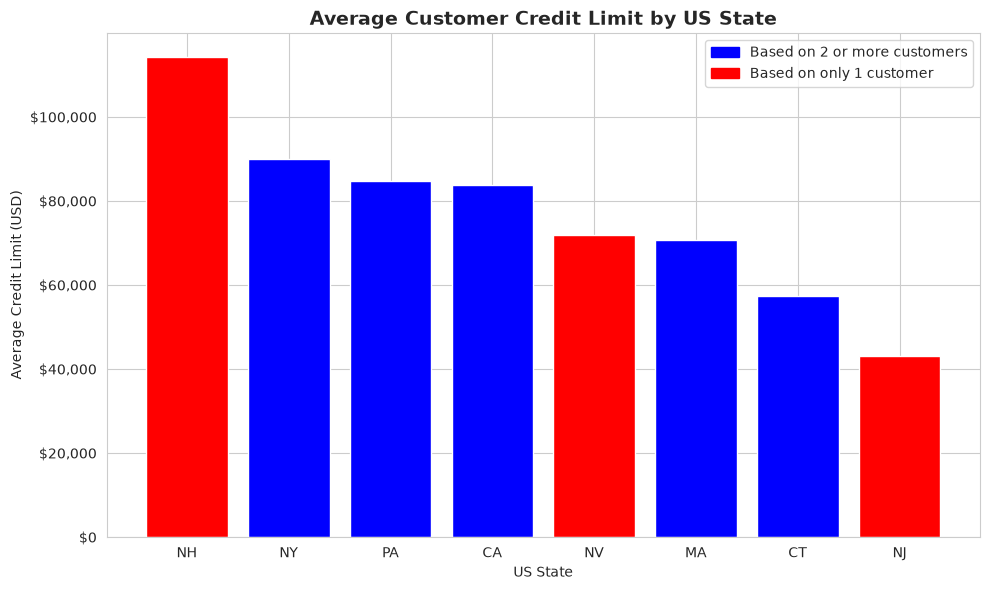

In [6]:
# Replace None with your visual code
# Produce a visual to represent the average credit limit by state
#imports
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Patch 

#creating the bar chart since it shows clear comparisons easily at a glance
sns.set_style('whitegrid')
fig, ax = plt.subplots(figsize = (10, 6))

#the red bars will represent the states whose avaerage came just from one customer and its only 3 states otherwise blue
colors = ['red' if n==1 else 'blue'
           for n in avg_credit_by_state['num_customers']]
bars = ax.bar(avg_credit_by_state['state'],
              avg_credit_by_state['avg_credit_limit'],
              color = colors)
#the axis
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.set_title('Average Customer Credit Limit by US State', fontsize=14, fontweight='bold')
ax.set_xlabel('US State')
ax.set_ylabel('Average Credit Limit (USD)')

#legends for the bars colour
ax.legend(handles=[Patch(color='blue', label='Based on 2 or more customers'),
                   Patch(color='red', label='Based on only 1 customer')],
          loc='upper right')

plt.tight_layout()
plt.show()


### Step 5: Top Customers - Visual Required
The company is approaching its 10 year anniversary and wants to acknowledge and thank its top customers with personalized communication. They have asked you to determine the top 10 customers based on the total amount of payments made, making sure to return the customer name for clarity. 

Execute a SQl query that returns the information required to address this ask.


In [7]:
# Replace None with your code
top_customer_query = ''' 
SELECT customers.customerNumber,
       customers.customerName,
       ROUND(SUM(CAST(payments.amount AS REAL)), 2) AS total_payments
FROM customers
JOIN payments
ON customers.customerNumber = payments.customerNumber
GROUP BY customers.customerNumber, customers.customerName
ORDER BY total_payments DESC
LIMIT 10;'''

top_customers = pd.read_sql(top_customer_query, conn)
top_customers

,customerNumber,customerName,total_payments
0,141,Euro+ Shopping Channel,715738.98
1,124,Mini Gifts Distributors Ltd.,584188.24
2,114,"Australian Collectors, Co.",180585.07
3,151,Muscle Machine Inc,177913.95
4,148,"Dragon Souveniers, Ltd.",156251.03
5,323,"Down Under Souveniers, Inc",154622.08
6,187,"AV Stores, Co.",148410.09
7,276,"Anna's Decorations, Ltd",137034.22
8,321,Corporate Gift Ideas Co.,132340.78
9,146,"Saveley & Henriot, Co.",130305.35


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

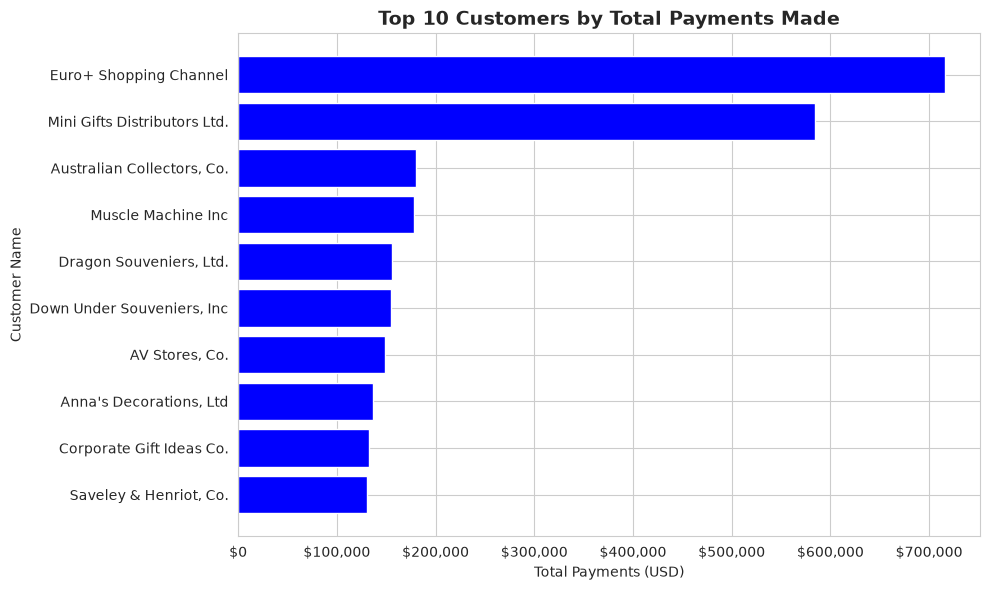

In [8]:
# Replace None with your visual code
# Produce a visual to represent the top ten customers in terms of total payments
#imports
import matplotlib.pyplot as plt
import seaborn as sns 

sns.set_style('whitegrid')
fig, ax = plt.subplots(figsize = (10, 6))

ax.barh(top_customers['customerName'],
        top_customers['total_payments'],
        color = 'blue')

ax.invert_yaxis()
ax.xaxis.set_major_formatter('${x:,.0f}')
ax.set_title('Top 10 Customers by Total Payments Made', fontsize=14, fontweight='bold')
ax.set_xlabel('Total Payments (USD)')
ax.set_ylabel('Customer Name')

plt.tight_layout()
plt.show()

### Step 6: Top Customer + Product Quantities
The product team is running an analysis on popular and common products sold to each customer in order to try and determine what new products they should be looking at to include in their catalog. This data will also be used by individual sales reps to recommend similar products to each customer next time they place an order. 

They have asked you to query information, for each customer, about any product they have purchased 10 or more units of. In addition they would like the full set of data to be sorted in ascending order by the total amount purchased.

Execute a SQl query that returns the information required to address this ask.

Hint: For this one, you'll need to make use of HAVING, GROUP BY, and ORDER BY — make sure you get the order of them correct!

In [9]:
# Replace None with you code
customer_product_query = ''' 
SELECT customers.customerNumber,
       customers.customerName,
       products.productCode,
       products.ProductName,
SUM(CAST(orderdetails.quantityOrdered AS INTEGER)) AS total_quantity
FROM customers
JOIN orders
  ON customers.customerNumber = orders.customerNumber
JOIN orderdetails
  ON orders.orderNumber = orderdetails.orderNumber
JOIN products 
  ON orderdetails.productCode = products.productCode
GROUP BY customers.customerNumber,
         customers.customerName,
         products.productCode,
         products.ProductName
HAVING SUM(CAST(orderdetails.quantityOrdered AS INTEGER)) >=10
ORDER BY total_quantity ASC;'''

customer_products = pd.read_sql(customer_product_query, conn)
customer_products

,customerNumber,customerName,productCode,productName,total_quantity
0,314,Petit Auto,S18_2949,1913 Ford Model T Speedster,10
1,412,"Extreme Desk Decorations, Ltd",S24_4620,1961 Chevrolet Impala,10
2,119,La Rochelle Gifts,S32_2509,1954 Greyhound Scenicruiser,11
3,328,Tekni Collectables Inc.,S700_1691,American Airlines: B767-300,11
4,450,The Sharp Gifts Warehouse,S24_3191,1969 Chevrolet Camaro Z28,13
...,...,...,...,...,...
2526,141,Euro+ Shopping Channel,S24_3432,2002 Chevy Corvette,174
2527,141,Euro+ Shopping Channel,S12_4473,1957 Chevy Pickup,183
2528,141,Euro+ Shopping Channel,S24_1444,1970 Dodge Coronet,197
2529,141,Euro+ Shopping Channel,S24_2840,1958 Chevy Corvette Limited Edition,245


### Step 7: Product Analysis - Visual Required

The product team is looking into the demand across its different product lines. They are conducting a comprehensive review of its product portfolio and inventory management strategies. You have been asked to query data pertaining to each different product line, that contains the total quantity ordered and the total number of products for each respective product line. By examining the number of products and total quantity ordered for each product line, the company aims to:
1. Optimize product mix:
    - Identify which product lines have the most diverse offerings (high number of products)
    - Determine which lines are most popular (high total quantity ordered)
    - Compare if lines with more products necessarily lead to more orders
2. Improve inventory management:
    - Adjust stock levels based on the popularity of each product line
    - Identify potential overstocking in lines with low order quantities
    - Ensure adequate variety in high-performing product lines
3. Adjust marketing strategy:
    - Focus promotional efforts on product lines with high potential (many products but lower order quantities)
    - Capitalize on the popularity of high-performing lines in marketing campaigns
4. Advise Product development:
    - Invest in expanding product ranges for lines with high order quantities
    - Consider phasing out or revamping product lines with low numbers of products and low order quantities

Hint: Think about how you can and might have to utilize SQL DISTINCT statement

Execute a SQl query that returns the information required to address this ask.

In [10]:
# Replace None with your code
#Number of products and total quantity ordered per product line
product_lines_query = ''' 
SELECT productlines.productLine,
       COUNT (DISTINCT products.productCode) AS num_products,
       SUM(CAST(orderdetails.quantityOrdered AS INTEGER)) AS total_quantity_ordered
FROM productlines
JOIN products
  ON productlines.productLine = products.productLine
LEFT JOIN orderdetails
    ON products.productCode = orderdetails.productCode
GROUP BY productlines.productLine
ORDER BY total_quantity_ordered DESC;'''

product_lines = pd.read_sql(product_lines_query, conn)
product_lines

,productLine,num_products,total_quantity_ordered
0,Classic Cars,38,35582
1,Vintage Cars,24,22933
2,Motorcycles,13,12778
3,Planes,12,11872
4,Trucks and Buses,11,11001
5,Ships,9,8532
6,Trains,3,2818


Once you have the information returned in a dataframe, select an appropriate visualization to represent the relationship between total quantity ordered and the number of products in order to perform a preliminary investigation into the question of if more products lead to more orders. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

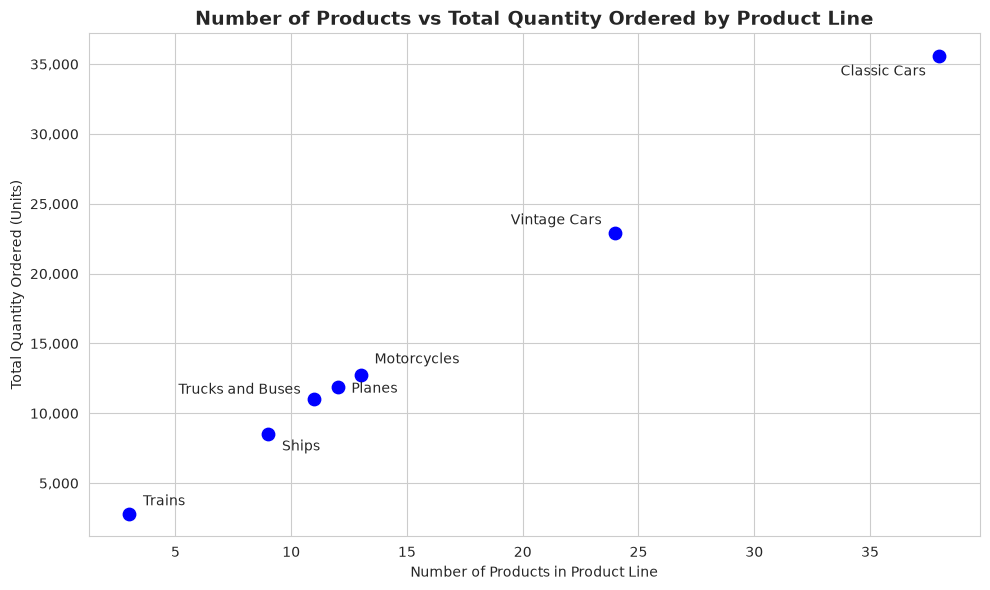

In [11]:
# Replace None with your visual code
# Produce a visual to represent the the relation between number of products and the total amount ordered
#imports
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(product_lines['num_products'],
           product_lines['total_quantity_ordered'],
           color='blue', s=80)

# Label each dot with its product line (offsets keep the labels from overlapping)
offsets = {'Motorcycles': (10, 8, 'left'),
           'Planes': (10, -4, 'left'),
           'Trucks and Buses': (-10, 4, 'right'),
           'Ships': (10, -12, 'left'),
           'Trains': (10, 6, 'left'),
           'Vintage Cars': (-10, 6, 'right'),
           'Classic Cars': (-10, -14, 'right')}

for _, row in product_lines.iterrows():
    dx, dy, ha = offsets[row['productLine']]
    ax.annotate(row['productLine'],
                (row['num_products'], row['total_quantity_ordered']),
                textcoords='offset points', xytext=(dx, dy), ha=ha)

ax.xaxis.set_major_formatter('{x:,.0f}')
ax.yaxis.set_major_formatter('{x:,.0f}')
ax.set_title('Number of Products vs Total Quantity Ordered by Product Line',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Number of Products in Product Line')
ax.set_ylabel('Total Quantity Ordered (Units)')

plt.tight_layout()
plt.show()

## Reflection Question:

Please explain your choice in the type of visual you used in order to highlight and represent the data from the above query. In a non-technical manner explain why that chart type makes sense for the information being conveyed. What does this visual convey in the context of the question it was asked for?

## Type your answer in markdown here!

- I used a scatter plot to create my visual because the question asks whether the number of products and total orders , are connected. A bar chart would show one number at a time and a line graph is for change over time that is why scatter plot is the right option.</br>
- Each dot represents a product line and we can clearly see that product lines with more products receive more orders since the dots rise steadily.</br>
- Classic cars  is at the top right corner with most products of 38 and most units ordered, about 35600</br>
- Trains is at the bottom left corner with the fewest products of 3 and about 2800 units ordered</br>
- According to the analysis and answers, product lines with more products sell more units.</br>

### Step 8: Remote Offices
Upper management is considering a shift to hybrid and remote work for certain locations and roles. They have tasked you with providing them data about employees who work in any office that has fewer than 5 total employees so they can better understand how to support those employees remotely when offices are shut down. 

Be sure to include information about the employees job and supervisor so management can adjust everyone to remote work properly.

Hint: Utilize a subquery to find the relevant offices

Execute a SQl query that returns the information required to address this ask.

In [12]:
# Replace None with your code
remote_office_query = ''' 
SELECT employees.employeeNumber,
       employees.firstName,
       employees.lastName,
       employees.jobTitle,
       employees.officeCode,
       supervisors.firstName AS supervisorFirstName,
       supervisors.lastName AS supervisorLastName,
       supervisors.jobTitle AS supervisorJobTitle
FROM employees
LEFT JOIN employees AS supervisors
   ON employees.reportsTo = supervisors.employeeNumber
WHERE employees.officeCode IN (SELECT officeCode
                               FROM employees
                               GROUP BY officeCode
                               HAVING COUNT(*) < 5
                        )
ORDER BY employees.officeCode,employees.lastName;'''

remote_offices = pd.read_sql(remote_office_query, conn)
remote_offices

,employeeNumber,firstName,lastName,jobTitle,officeCode,supervisorFirstName,supervisorLastName,supervisorJobTitle
0,1188,Julie,Firrelli,Sales Rep,2,Anthony,Bow,Sales Manager (NA)
1,1216,Steve,Patterson,Sales Rep,2,Anthony,Bow,Sales Manager (NA)
2,1286,Foon Yue,Tseng,Sales Rep,3,Anthony,Bow,Sales Manager (NA)
3,1323,George,Vanauf,Sales Rep,3,Anthony,Bow,Sales Manager (NA)
4,1625,Yoshimi,Kato,Sales Rep,5,Mami,Nishi,Sales Rep
5,1621,Mami,Nishi,Sales Rep,5,Mary,Patterson,VP Sales
6,1611,Andy,Fixter,Sales Rep,6,William,Patterson,Sales Manager (APAC)
7,1619,Tom,King,Sales Rep,6,William,Patterson,Sales Manager (APAC)
8,1612,Peter,Marsh,Sales Rep,6,William,Patterson,Sales Manager (APAC)
9,1088,William,Patterson,Sales Manager (APAC),6,Mary,Patterson,VP Sales


## Reflection Question:

Describe how you decided on the subquery that you used in the query above? This answer can be technically in nature, describing your thought process in how the main query is utilizing the subquery to return the correct data.

## Type your answer in markdown here!

- The question is about employees but its filtered with the offices(offices with fewer than 5 employees) looking at this problem you can't actually know the offices that meet the condition, without counting the employees in each office</br>
- I decided to use a subquery to do the counting of the employees before the main query does the filtering.</br>
- The subquery groups the employees by officeCode, counts each group and uses HAVING COUNT(*) < 5 so as to keep only the small offices.</br>
- I used HAVING and not WHERE because the filter is on COUNT and counts only exist after grouping.</br>
- Manually typing the would give the same output today but in case of change in staffing it would break</br>
- Therefore the main query uses WHERE employees.officeCode IN(...) so that the employees so that the employees whose office is on the subquery's list are kept and the join adds each employee to the supervisor</br>

### Step 9: Close the Connection

Now that you are finished executing your queries and retrieving the required information you always want to make sure to close the connection to your database.

In [13]:
# Replace None with your code
conn.close()

### End of Guided Section
In this initial portion of the assessment, you produced several data queries and visualizations for a model company, mainly focused around its customer and product data. You wrote and engineered specific SQL queries to address pertinent questions and asks from the company. Along the way, you utilized many of the major concepts and keywords associated with SQL SELECT queries: FROM, WHERE, GROUP BY, HAVING, ORDER BY, JOIN, SUM, COUNT, and AVG.

## Part 2: Exploratory Analysis with SQL
In this open-ended exploratory section, you will analyze real-world data from the movie industry. As a data analyst, you have the freedom to investigate questions and topics that intrigue you within this dataset. The database schema and Entity-Relationship Diagram (ERD) are provided below for your reference. A general overview and instructions are also provided below.

In [14]:
# Run this cell without changes
import zipfile

zip_file_path = 'im.db.zip'
extract_to_path = './'

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to_path)

# Connection
conn4 = sqlite3.connect('im.db')

# Schema
schema_df = pd.read_sql("""
SElECT * FROM sqlite_master                        
""", conn4)
schema_df

,type,name,tbl_name,rootpage,sql
0,table,movie_basics,movie_basics,2,"CREATE TABLE ""movie_basics"" (\n""movie_id"" TEXT..."
1,table,directors,directors,3,"CREATE TABLE ""directors"" (\n""movie_id"" TEXT,\n..."
2,table,known_for,known_for,4,"CREATE TABLE ""known_for"" (\n""person_id"" TEXT,\..."
3,table,movie_akas,movie_akas,5,"CREATE TABLE ""movie_akas"" (\n""movie_id"" TEXT,\..."
4,table,movie_ratings,movie_ratings,6,"CREATE TABLE ""movie_ratings"" (\n""movie_id"" TEX..."
5,table,persons,persons,7,"CREATE TABLE ""persons"" (\n""person_id"" TEXT,\n ..."
6,table,principals,principals,8,"CREATE TABLE ""principals"" (\n""movie_id"" TEXT,\..."
7,table,writers,writers,9,"CREATE TABLE ""writers"" (\n""movie_id"" TEXT,\n ..."


## The Data

![movie ERD](images/movie_data_erd.jpeg)
### Database Content:

- Source: IMDB
- Time Range: Movies released between 2010 and 2019
- Note: Exclude any movies with a start_year after 2019 as this data is not current or accurate

Available Data Categories:
- Genre
- Runtime
- Personnel (writers, directors, actors)
- Movie ratings

### Objectives:

Initial Exploration:
- Use SQL in combination with Pandas to explore the database
- Identify interesting trends, patterns, or relationships in the data

Business Question Formulation:
- Develop at least one substantial business question for deeper analysis
- Ensure the question is relevant, specific, and can be addressed with the available data

Data Cleaning Assessment:
- Identify potential data cleaning tasks necessary for your deeper analysis
- Note: You are not required to perform the cleaning, only to recognize and list the necessary tasks

Null Value Handling:
- Be aware that the dataset contains null values in certain fields
- Exclude these null values from your exploration
- Do not attempt to input or fill in missing information

### Deliverables:

You need to produce a short slide presentation (3-5 slides) that highlights the three key deliverables below. Utilize a data visualization to support the second deliverable.

1. A summary of your initial data exploration findings
    - Can be bulleted or sentence form
2. At least one well-formulated business question for further analysis
    - Should stem from a relevant trend or pattern your initial exploration identified
3. A list of potential data cleaning tasks identified during your exploration
    - This can and should include things like data normalization/standardization and null handling

Tips for Success:

Begin with broad exploratory queries to understand the data's scope and content. Then focus on honing in on interesting relationships between different data categories. Consider industry trends, audience preferences, or financial aspects when formulating your business question. Pay attention to data quality issues, inconsistencies, or limitations that might affect your analysis. Remember, the goal is to demonstrate your analytical thinking and ability to derive meaningful insights from complex datasets. Good luck with your exploration!

NOTE: You do not need to explore every aspect of this database. Find something that you think is interesting or relevant about the data and focus your exploration there.

In [15]:
# Begin your code here
#Checking the size of the tables
tables =['movie_basics', 'movie_ratings', 'movie_akas', 'persons', 'principals', 'directors', 'writers', 'known_for']

row_counts ={}
for table in tables:
    count = pd.read_sql(f'SELECT COUNT(*) AS n FROM {table} ;', conn4)['n'][0]
    row_counts[table] = count

pd.Series(row_counts, name ='number_of_rows')

movie_basics      146144
movie_ratings      73856
movie_akas        331703
persons           606648
principals       1028186
directors         291174
writers           255873
known_for        1638260
Name: number_of_rows, dtype: int64

In [16]:
#preview the movies
movies = pd.read_sql('''
SELECT * FROM movie_basics WHERE start_year <= 2019 LIMIT 10;''', conn4)
movies

,movie_id,primary_title,original_title,start_year,runtime_minutes,genres
0,tt0063540,Sunghursh,Sunghursh,2013,175.0,"Action,Crime,Drama"
1,tt0066787,One Day Before the Rainy Season,Ashad Ka Ek Din,2019,114.0,"Biography,Drama"
2,tt0069049,The Other Side of the Wind,The Other Side of the Wind,2018,122.0,Drama
3,tt0069204,Sabse Bada Sukh,Sabse Bada Sukh,2018,NaN,"Comedy,Drama"
4,tt0100275,The Wandering Soap Opera,La Telenovela Errante,2017,80.0,"Comedy,Drama,Fantasy"
5,tt0111414,A Thin Life,A Thin Life,2018,75.0,Comedy
6,tt0112502,Bigfoot,Bigfoot,2017,NaN,"Horror,Thriller"
7,tt0137204,Joe Finds Grace,Joe Finds Grace,2017,83.0,"Adventure,Animation,Comedy"
8,tt0139613,O Silêncio,O Silêncio,2012,NaN,"Documentary,History"
9,tt0144449,Nema aviona za Zagreb,Nema aviona za Zagreb,2012,82.0,Biography


### Preview of the main table

- The idea here is to preview the main table and we can see it shows:
- the first 10 movies with a start year of 2019 or earlier.
- Each movie has an ID, a primary title, an original title, a start year, a runtime in minutes and a genre.
- Three things stand out:
- some runtimes are missing showing NaN 
- The genres column stores several genres in one cell
- The primary and original title can differ

In [17]:
#missing values
movies_all = pd.read_sql('''SELECT * FROM movie_basics WHERE start_year <=2019;''', conn4)

movies_all.isnull().sum()

movie_id               0
primary_title          0
original_title        20
start_year             0
runtime_minutes    30765
genres              5359
dtype: int64

### Checking the missing values in movie_basics (movies upto the year 2019)
- From the results we can see the runtime_minutes has 30765 missing values for movies
- genre has 5359 missing values
- original_title has 20 missing values
- movie_id, primary_title and start year all have complete values.
- if runtime_minutes and genres are used for analysis they will cover fewer movies than the full table.

In [18]:
#checking what percentage of the total this covers so that it helps to wknow how to handle the missing data.
print("Total movies up to 2019:", len(movies_all))

(movies_all.isnull().mean() * 100).round(2)

Total movies up to 2019: 145081


movie_id            0.00
primary_title       0.00
original_title      0.01
start_year          0.00
runtime_minutes    21.21
genres              3.69
dtype: float64

### The percentage of missing values.
 - There are 145081 movies upto 2019.
 - 21.21% of them have no runtime_minutes and 3.69% have no genre while only 0.01% are missing the original_title.
 - An analysis done with runtime_minutes would cover about 79% of the total movies , this means the null values can be excluded from the analysis.
 

In [19]:
#to check whether the number of movies changed over time.
movies_per_year = pd.read_sql(''' 
SELECT start_year,
       COUNT(*) AS num_movies
FROM movie_basics
WHERE start_year <= 2019
GROUP BY start_year
ORDER BY start_year;''', conn4)

movies_per_year

,start_year,num_movies
0,2010,11849
1,2011,12900
2,2012,13787
3,2013,14709
4,2014,15589
5,2015,16243
6,2016,17272
7,2017,17504
8,2018,16849
9,2019,8379


### Movies that were released per year
- The number of movies grows from 11849 in 2010 to a peak of 17504 in 2017.
- It dips slightly in 2018  to 16849 .
- The count for 2019 is 8379 which is about half of 2018.
- This can be because the data for the full year is invomplete.

In [20]:
#lets check the ratings of the movies.
rated_movies = pd.read_sql(''' 
SELECT movie_basics.*, movie_ratings.averagerating, movie_ratings.numvotes
FROM movie_basics
JOIN movie_ratings ON movie_basics.movie_id = movie_ratings.movie_id
WHERE movie_basics.start_year <= 2019;''', conn4)

print('Rated movies:', len(rated_movies))
rated_movies.isnull().sum()

Rated movies: 73856


movie_id              0
primary_title         0
original_title        0
start_year            0
runtime_minutes    7620
genres              804
averagerating         0
numvotes              0
dtype: int64

### Movies with ratings 
- Joining movies_basics to movies_ratings gives 73856 rated movies, which is about half of the total 145081 movies upto 2019
- Among the rated movies 7620 have no runtime_minutes and 804 have no genre.
- we can exclude the movies without a rating from this analysis of studying ratings.

In [21]:
#describing the rated movies.
rated_movies['runtime_minutes'].describe()

count    66236.000000
mean        94.654040
std        208.574111
min          3.000000
25%         81.000000
50%         91.000000
75%        104.000000
max      51420.000000
Name: runtime_minutes, dtype: float64

### Runtime summary (rated movies)
-  66,236 have a runtime of all the rated movies.
- The median runtime is 91 minutes and the middle half of movies lie between 81 and 104 minutes.
-  However, the longest runtime is 51,420 minutes and the shortest is 3 minutes, which are not realistic.
- The very large standard deviation (208.6) also points out that there are extreme values.
- These outliers should be listed as a data cleaning issue.

In [22]:
runtime_vs_rating = pd.read_sql('''
SELECT CASE WHEN runtime_minutes < 90 THEN '1. Under 90 min'
            WHEN runtime_minutes < 120 THEN '2. 90-119 min'
            WHEN runtime_minutes < 150 THEN '3. 120-149 min'
            ELSE '4. 150+ min' END AS runtime_group,
       COUNT(*) AS num_movies,
       ROUND(AVG(movie_ratings.averagerating), 2) AS avg_rating
FROM movie_basics
JOIN movie_ratings
    ON movie_basics.movie_id = movie_ratings.movie_id
WHERE movie_basics.start_year <= 2019
  AND movie_basics.runtime_minutes IS NOT NULL
GROUP BY runtime_group
ORDER BY runtime_group;''', conn4)

runtime_vs_rating

,runtime_group,num_movies,avg_rating
0,1. Under 90 min,28099,6.39
1,2. 90-119 min,30649,6.22
2,3. 120-149 min,5960,6.44
3,4. 150+ min,1528,6.64


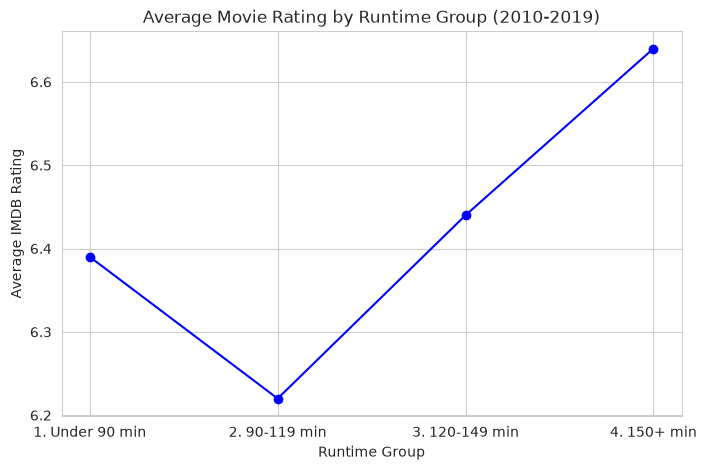

In [23]:
# visual of the table
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(runtime_vs_rating['runtime_group'],
         runtime_vs_rating['avg_rating'],
         marker='o', color='blue')

plt.title('Average Movie Rating by Runtime Group (2010-2019)')
plt.xlabel('Runtime Group')
plt.ylabel('Average IMDB Rating')
plt.grid(True)
plt.show()

### Average rating by runtime group

- Among 66236 rated movies with a runtime, movies of 90 to 119 minutes are 30,649 movies and have the lowest average rating at 6.22.
- Shorter movies which are under 90 minutes have an average of 6.39.
- longer movies rate higher at an average of 6.44 for 120 to 149 minutes and 6.64 for 150 minutes or more.
- The differences are small of  about 0.4 points. 
- Runtimes were grouped into bands so that extreme values, such as the 51,420-minute entry, fall into the top band and do not distort the averages.

### THE BUSINESS QUESTION

Why do the standard length movies that have a runtime of between 90 to 119 minutes have a lower rating that both the shorter movies that have a runtime of under 90 minutes and the longer movies of 120+ minutes. Is this because of the genre or by how many people rated the movie?

### DATA CLEANING TASKS.

1. **Missing runtimes:** 21.21% of the total movies (30,765) have no runtime, and 10.3% of rated movies. These are excluded from the analysis and not filled in.
2. **Missing genres:** 3.69% of the total movies (5,359) have no genre, to be excluded in a genre analysis.
3. **Unrealistic runtimes:** runtimes range from 3 to 51,420 minutes. Extreme values need checking and a sensible limit, meaning there are some outliers.
4. **Genres stored in one cell:** values such as "Action,Crime,Drama" need splitting into separate genres before analysing by genre.
5. **Incomplete 2019 data:** only 8,379 movies, about half of 2018, so 2019 should be treated with caution or left out of year to year comparisons.
6. **Many movies have no rating:** only 73,856 of 145,081 movies (about 51%) have ratings, so results apply only to rated movies.
7. **Titles:** 20 movies have no original title.Primary and original titles can be in different languages or spellings, which would need standardising.

## Summary of initial exploration findings

- The database covers 145,081 movies from 2010 to 2019, and 73,856 (about 51%) have a rating.
- Releases grew by about 48% from 2010 (11,849) to 2017 (17,504). The 2019 count (8,379) is about half of 2018, which suggests the 2019 data may be incomplete.
- The median runtime is 91 minutes, but 21.2% of movies have no runtime and some runtimes are unrealistic of up to 51,420 minutes.
- Genres are stored together in one cell, and 3.7% of movies have no genre.
- Average rating varies by runtime group: it is lowest for movies of 90 to 119 minutes (6.22) and higher for shorter (6.39) and longer movies (up to 6.64 for 150+ minutes).

In [24]:
#clossing the connection to the movies data base
conn4.close()